In [1]:
#IMPORT CODE

%matplotlib widget

import os
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from cartopy.feature import ShapelyFeature
import cartopy.crs as ccrs
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import folium
import matplotlib.colors as mcolors #function for normalizing colours for colourbar features
import numpy as np
plt.ion() # make the plotting interactive

#LOAD DATA

res_route = gpd.read_file('London_data/restricted_route.json')

cycle = gpd.read_file('London_data/cycle_lane_track.json')  #2017/18 cycle routes
london = gpd.read_file('London_data/London_Boroughs.gpkg')
method_new = pd.read_csv('London_data/method.csv', skiprows=6)
method_old = pd.read_csv('London_data/method.csv.csv', skiprows=6)

In [2]:
#filter the data to show true cycle infrastructure
cycle_t = cycle.drop(columns=['CLT_CARR',
                              'CLT_SHARED',
                              'CLT_ADVIS',
                              'CLT_PRIORI',
                              'CLT_BBYPAS',
                              'CLT_PARKR',
                              'CLT_WATERR',
                              'CLT_PTIME',
                              'CLT_ACCESS',
                              'CLT_COLOUR',
                              'PHOTO1_URL',
                              'PHOTO2_URL'])


In [3]:
cycle_t


,FEATURE_ID,SVDATE,CLT_SEGREG,CLT_STEPP,CLT_PARSEG,CLT_MANDAT,CLT_CONTRA,CLT_BIDIRE,CLT_CBYPAS,BOROUGH,geometry
0,RWG154837,2017-10-14,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,Barking & Dagenham,"LINESTRING (0.13534 51.57164, 0.13348 51.5713)"
1,RWG154839,2017-10-14,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,Barking & Dagenham,"LINESTRING (0.13189 51.57102, 0.13128 51.57093..."
2,RWG154848,2017-10-14,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,Barking & Dagenham,"LINESTRING (0.1353 51.56129, 0.13484 51.56133,..."
3,RWG154853,2017-10-15,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,Barking & Dagenham,"LINESTRING (0.14181 51.57241, 0.1413 51.57365)"
4,RWG155003,2017-10-17,FALSE,FALSE,FALSE,TRUE,FALSE,FALSE,FALSE,Barking & Dagenham,"LINESTRING (0.14087 51.5591, 0.14069 51.55909,..."
...,...,...,...,...,...,...,...,...,...,...,...
24971,RWG154170,2017-12-06,FALSE,FALSE,FALSE,FALSE,FALSE,TRUE,FALSE,Wandsworth,"MULTILINESTRING ((-0.23098 51.46738, -0.23076 ..."
24972,RWG107707,2017-11-02,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,Southwark,"LINESTRING (-0.0749 51.44973, -0.0745 51.44941)"
24973,RWG221075,2018-02-09,FALSE,FALSE,FALSE,FALSE,FALSE,TRUE,FALSE,NaN,"MULTILINESTRING ((-0.019 51.54538, -0.01895 51..."
24974,RWG276415,2018-03-13,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,NaN,"LINESTRING (-0.04599 51.56216, -0.04553 51.56236)"


In [4]:
#delete end rows


In [5]:
#lets compare the number of people cycling to work between 2011 and 2021, and see if
#there is a pattern of cycle infrastructure promoting the use of cycles
method_old

,Area,mnemonic,All categories: Method of travel to work (2001 specification),Bicycle
0,ualad09:Barking and Dagenham,E09000002,58444.0,939.0
1,ualad09:Barnet,E09000003,129112.0,1593.0
2,ualad09:Bexley,E09000004,74670.0,927.0
3,ualad09:Brent,E09000005,115221.0,2054.0
4,ualad09:Bromley,E09000006,111405.0,1366.0
5,ualad09:Camden,E09000007,272367.0,13909.0
6,ualad09:City of London,E09000001,356706.0,13501.0
7,ualad09:Croydon,E09000008,120398.0,1524.0
8,ualad09:Ealing,E09000009,132461.0,3211.0
9,ualad09:Enfield,E09000010,105493.0,1647.0


In [6]:
#our 2011 table is missing a percentage column


In [7]:
method_old['bike%2011'] = method_old['Bicycle']/method_old['All categories: Method of travel to work (2001 specification)']*100

In [8]:
method_old.head()

,Area,mnemonic,All categories: Method of travel to work (2001 specification),Bicycle,bike%2011
0,ualad09:Barking and Dagenham,E09000002,58444.0,939.0,1.606666
1,ualad09:Barnet,E09000003,129112.0,1593.0,1.233813
2,ualad09:Bexley,E09000004,74670.0,927.0,1.241462
3,ualad09:Brent,E09000005,115221.0,2054.0,1.782661
4,ualad09:Bromley,E09000006,111405.0,1366.0,1.226157


In [9]:
method_new.head()

,Area,mnemonic,Total: All usual residents aged 16 years and over in employment the week before the census,%,"Underground, metro, light rail, tram",%.1,Train,%.2,"Bus, minibus or coach",%.3,"Motorcycle, scooter or moped",%.4,Driving a car or van,%.5,Bicycle,%.6,On foot,%.7
0,ladu2023:Barking and Dagenham,E09000002,94586.0,100.0,15301.0,16.2,8660.0,9.2,9690.0,10.2,599.0,0.6,30732.0,32.5,1218.0,1.3,4464.0,4.7
1,ladu2023:Barnet,E09000003,186175.0,100.0,20758.0,11.1,4690.0,2.5,15090.0,8.1,1197.0,0.6,46797.0,25.1,2162.0,1.2,9361.0,5.0
2,ladu2023:Bexley,E09000004,117983.0,100.0,2838.0,2.4,12164.0,10.3,7763.0,6.6,767.0,0.7,42503.0,36.0,995.0,0.8,5258.0,4.5
3,ladu2023:Brent,E09000005,160997.0,100.0,24200.0,15.0,8267.0,5.1,21439.0,13.3,1801.0,1.1,34917.0,21.7,4074.0,2.5,11000.0,6.8
4,ladu2023:Bromley,E09000006,162122.0,100.0,3146.0,1.9,15214.0,9.4,8069.0,5.0,966.0,0.6,45304.0,27.9,1784.0,1.1,7029.0,4.3


In [10]:
#find a more accurate value of percentage in our new dataset
#we could alter the significant figure length of the old dataset, 
#but we can also use the exisitng data to create a more accurate overall picture
method_new['bike_pc'] = method_new['Bicycle']/method_new['Total: All usual residents aged 16 years and over in employment the week before the census']*100

#lets add the 2021 percentages to our 2011 dataset
method_old['bike_2021'] = method_new['bike_pc']

method_old.head()

In [11]:
method_old.head()

,Area,mnemonic,All categories: Method of travel to work (2001 specification),Bicycle,bike%2011,bike_2021
0,ualad09:Barking and Dagenham,E09000002,58444.0,939.0,1.606666,1.287717
1,ualad09:Barnet,E09000003,129112.0,1593.0,1.233813,1.161273
2,ualad09:Bexley,E09000004,74670.0,927.0,1.241462,0.843342
3,ualad09:Brent,E09000005,115221.0,2054.0,1.782661,2.530482
4,ualad09:Bromley,E09000006,111405.0,1366.0,1.226157,1.100406


In [12]:


#add a column to demonstrate change in bicycle usage
method_old['bike_change'] = method_old['bike_2021']-method_new['bike_pc']*10

In [13]:
method_old

,Area,mnemonic,All categories: Method of travel to work (2001 specification),Bicycle,bike%2011,bike_2021,bike_change
0,ualad09:Barking and Dagenham,E09000002,58444.0,939.0,1.606666,1.287717,-11.589453
1,ualad09:Barnet,E09000003,129112.0,1593.0,1.233813,1.161273,-10.451457
2,ualad09:Bexley,E09000004,74670.0,927.0,1.241462,0.843342,-7.590077
3,ualad09:Brent,E09000005,115221.0,2054.0,1.782661,2.530482,-22.774337
4,ualad09:Bromley,E09000006,111405.0,1366.0,1.226157,1.100406,-9.903653
5,ualad09:Camden,E09000007,272367.0,13909.0,5.106713,3.895192,-35.056726
6,ualad09:City of London,E09000001,356706.0,13501.0,3.784910,3.568759,-32.118834
7,ualad09:Croydon,E09000008,120398.0,1524.0,1.265802,1.278714,-11.508429
8,ualad09:Ealing,E09000009,132461.0,3211.0,2.424110,2.871573,-25.844160
9,ualad09:Enfield,E09000010,105493.0,1647.0,1.561241,1.417996,-12.761964


In [14]:
methold_old = method_old.drop(range(34,36))
#this is not working for some reason


method_old

In [15]:
method_old.head()

,Area,mnemonic,All categories: Method of travel to work (2001 specification),Bicycle,bike%2011,bike_2021,bike_change
0,ualad09:Barking and Dagenham,E09000002,58444.0,939.0,1.606666,1.287717,-11.589453
1,ualad09:Barnet,E09000003,129112.0,1593.0,1.233813,1.161273,-10.451457
2,ualad09:Bexley,E09000004,74670.0,927.0,1.241462,0.843342,-7.590077
3,ualad09:Brent,E09000005,115221.0,2054.0,1.782661,2.530482,-22.774337
4,ualad09:Bromley,E09000006,111405.0,1366.0,1.226157,1.100406,-9.903653


In [16]:
method_old = method_old.drop(range(34,37))

method_old

In [17]:
method_old

,Area,mnemonic,All categories: Method of travel to work (2001 specification),Bicycle,bike%2011,bike_2021,bike_change
0,ualad09:Barking and Dagenham,E09000002,58444.0,939.0,1.606666,1.287717,-11.589453
1,ualad09:Barnet,E09000003,129112.0,1593.0,1.233813,1.161273,-10.451457
2,ualad09:Bexley,E09000004,74670.0,927.0,1.241462,0.843342,-7.590077
3,ualad09:Brent,E09000005,115221.0,2054.0,1.782661,2.530482,-22.774337
4,ualad09:Bromley,E09000006,111405.0,1366.0,1.226157,1.100406,-9.903653
5,ualad09:Camden,E09000007,272367.0,13909.0,5.106713,3.895192,-35.056726
6,ualad09:City of London,E09000001,356706.0,13501.0,3.784910,3.568759,-32.118834
7,ualad09:Croydon,E09000008,120398.0,1524.0,1.265802,1.278714,-11.508429
8,ualad09:Ealing,E09000009,132461.0,3211.0,2.424110,2.871573,-25.844160
9,ualad09:Enfield,E09000010,105493.0,1647.0,1.561241,1.417996,-12.761964


In [18]:
#37 is still there, drop it individually
method_old = method_old.drop(37)

In [19]:
#compare CRS

print(method_old.crs, cycle_t.crs)

AttributeError: 'DataFrame' object has no attribute 'crs'

In [20]:
#we see an error as method_old is not recognised as geodataframes
#lets create a universal crs using our bike usage table
method_old.crs

AttributeError: 'DataFrame' object has no attribute 'crs'

In [21]:
method_new

,Area,mnemonic,Total: All usual residents aged 16 years and over in employment the week before the census,%,"Underground, metro, light rail, tram",%.1,Train,%.2,"Bus, minibus or coach",%.3,"Motorcycle, scooter or moped",%.4,Driving a car or van,%.5,Bicycle,%.6,On foot,%.7,bike_pc
0,ladu2023:Barking and Dagenham,E09000002,94586.0,100.0,15301.0,16.2,8660.0,9.2,9690.0,10.2,599.0,0.6,30732.0,32.5,1218.0,1.3,4464.0,4.7,1.287717
1,ladu2023:Barnet,E09000003,186175.0,100.0,20758.0,11.1,4690.0,2.5,15090.0,8.1,1197.0,0.6,46797.0,25.1,2162.0,1.2,9361.0,5.0,1.161273
2,ladu2023:Bexley,E09000004,117983.0,100.0,2838.0,2.4,12164.0,10.3,7763.0,6.6,767.0,0.7,42503.0,36.0,995.0,0.8,5258.0,4.5,0.843342
3,ladu2023:Brent,E09000005,160997.0,100.0,24200.0,15.0,8267.0,5.1,21439.0,13.3,1801.0,1.1,34917.0,21.7,4074.0,2.5,11000.0,6.8,2.530482
4,ladu2023:Bromley,E09000006,162122.0,100.0,3146.0,1.9,15214.0,9.4,8069.0,5.0,966.0,0.6,45304.0,27.9,1784.0,1.1,7029.0,4.3,1.100406
5,ladu2023:Camden,E09000007,102511.0,100.0,10351.0,10.1,2852.0,2.8,6532.0,6.4,546.0,0.5,7074.0,6.9,3993.0,3.9,10620.0,10.4,3.895192
6,ladu2023:City of London,E09000001,5352.0,100.0,349.0,6.5,95.0,1.8,132.0,2.5,13.0,0.2,124.0,2.3,191.0,3.6,758.0,14.2,3.568759
7,ladu2023:Croydon,E09000008,189409.0,100.0,8146.0,4.3,17229.0,9.1,19903.0,10.5,1454.0,0.8,52381.0,27.7,2422.0,1.3,10018.0,5.3,1.278714
8,ladu2023:Ealing,E09000009,175026.0,100.0,20319.0,11.6,5788.0,3.3,18840.0,10.8,1531.0,0.9,42941.0,24.5,5026.0,2.9,11236.0,6.4,2.871573
9,ladu2023:Enfield,E09000010,143865.0,100.0,12557.0,8.7,7138.0,5.0,15289.0,10.6,788.0,0.5,46721.0,32.5,2040.0,1.4,8213.0,5.7,1.417996


In [22]:
#lets use our london data frame and merge

london.head()

,objectid,name,gss_code,hectares,nonld_area,ons_inner,sub_2011,geometry
0,1,Kingston upon Thames,E09000021,3726.117,0.000,F,South,"POLYGON ((516401.6 160201.8, 516407.3 160210.5..."
1,2,Croydon,E09000008,8649.441,0.000,F,South,"POLYGON ((535009.2 159504.7, 535005.5 159502, ..."
2,3,Bromley,E09000006,15013.487,0.000,F,South,"POLYGON ((540373.6 157530.4, 540361.2 157551.9..."
3,4,Hounslow,E09000018,5658.541,60.755,F,West,"POLYGON ((509703.4 175356.6, 509712.6 175361.8..."
4,5,Ealing,E09000009,5554.428,0.000,F,West,"POLYGON ((515647.2 178787.8, 515608.8 178787.3..."


In [23]:
travel_map = method_old.merge(london, left_on='mnemonic', right_on='gss_code', how='right')

In [24]:
travel_map.head()

,Area,mnemonic,All categories: Method of travel to work (2001 specification),Bicycle,bike%2011,bike_2021,bike_change,objectid,name,gss_code,hectares,nonld_area,ons_inner,sub_2011,geometry
0,ualad09:Kingston upon Thames,E09000021,72450.0,3042.0,4.198758,2.827162,-25.444455,1,Kingston upon Thames,E09000021,3726.117,0.000,F,South,"POLYGON ((516401.6 160201.8, 516407.3 160210.5..."
1,ualad09:Croydon,E09000008,120398.0,1524.0,1.265802,1.278714,-11.508429,2,Croydon,E09000008,8649.441,0.000,F,South,"POLYGON ((535009.2 159504.7, 535005.5 159502, ..."
2,ualad09:Bromley,E09000006,111405.0,1366.0,1.226157,1.100406,-9.903653,3,Bromley,E09000006,15013.487,0.000,F,South,"POLYGON ((540373.6 157530.4, 540361.2 157551.9..."
3,ualad09:Hounslow,E09000018,128880.0,4261.0,3.306176,2.922148,-26.299333,4,Hounslow,E09000018,5658.541,60.755,F,West,"POLYGON ((509703.4 175356.6, 509712.6 175361.8..."
4,ualad09:Ealing,E09000009,132461.0,3211.0,2.424110,2.871573,-25.844160,5,Ealing,E09000009,5554.428,0.000,F,West,"POLYGON ((515647.2 178787.8, 515608.8 178787.3..."


In [25]:
travel_map

,Area,mnemonic,All categories: Method of travel to work (2001 specification),Bicycle,bike%2011,bike_2021,bike_change,objectid,name,gss_code,hectares,nonld_area,ons_inner,sub_2011,geometry
0,ualad09:Kingston upon Thames,E09000021,72450.0,3042.0,4.198758,2.827162,-25.444455,1,Kingston upon Thames,E09000021,3726.117,0.000,F,South,"POLYGON ((516401.6 160201.8, 516407.3 160210.5..."
1,ualad09:Croydon,E09000008,120398.0,1524.0,1.265802,1.278714,-11.508429,2,Croydon,E09000008,8649.441,0.000,F,South,"POLYGON ((535009.2 159504.7, 535005.5 159502, ..."
2,ualad09:Bromley,E09000006,111405.0,1366.0,1.226157,1.100406,-9.903653,3,Bromley,E09000006,15013.487,0.000,F,South,"POLYGON ((540373.6 157530.4, 540361.2 157551.9..."
3,ualad09:Hounslow,E09000018,128880.0,4261.0,3.306176,2.922148,-26.299333,4,Hounslow,E09000018,5658.541,60.755,F,West,"POLYGON ((509703.4 175356.6, 509712.6 175361.8..."
4,ualad09:Ealing,E09000009,132461.0,3211.0,2.424110,2.871573,-25.844160,5,Ealing,E09000009,5554.428,0.000,F,West,"POLYGON ((515647.2 178787.8, 515608.8 178787.3..."
5,ualad09:Havering,E09000016,84726.0,885.0,1.044544,0.679591,-6.116316,6,Havering,E09000016,11445.735,210.763,F,East,"POLYGON ((553564 179127.1, 553558.8 179103.1, ..."
6,ualad09:Hillingdon,E09000017,164963.0,2358.0,1.429411,1.139316,-10.253843,7,Hillingdon,E09000017,11570.063,0.000,F,West,"POLYGON ((507187.7 174163.7, 507160.8 174181.7..."
7,ualad09:Harrow,E09000015,73804.0,707.0,0.957943,0.731783,-6.586051,8,Harrow,E09000015,5046.330,0.000,F,West,"POLYGON ((515767.2 186062.8, 515761 186057.3, ..."
8,ualad09:Brent,E09000005,115221.0,2054.0,1.782661,2.530482,-22.774337,9,Brent,E09000005,4323.270,0.000,F,West,"POLYGON ((515767.2 186062.8, 515860 186143.8, ..."
9,ualad09:Barnet,E09000003,129112.0,1593.0,1.233813,1.161273,-10.451457,10,Barnet,E09000003,8674.837,0.000,F,North,"POLYGON ((517435.2 194421.1, 517437.4 194420.3..."


In [26]:
#this raises an error as our travel map is not yet a geodataframe
#find out the original london crs and use this
london.crs
uni_crs=ccrs.OSGB()
#note that cartopy struggles with setting EPSG UK value as ccrs, use OSGB instead


travel_map = gpd.GeoDataFrame(travel_map, geometry='geometry', crs=uni_crs)
travel_map = travel_map.to_crs(uni_crs)

In [27]:
#add a shortcut function for a colour bar
def generate_handles(edgecolor, labels, alpha, travel_map, column, cmap_name='viridis'):
    handles = []
    cmap_name = plt.get_cmap(cmap_name)
    #create a vmin and vmax within function, 
    #normalize the color values in viridis to match our values
    vmin = travel_map[column].min()
    vmax = travel_map[column].max()
    sample_values = np.linspace(vmax, vmin)
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    for label, val in zip(labels, sample_values): #filter through whatever column we give to handles generator
        color_decimal = norm(val)
        color = cmap_name(color_decimal) #assign a color to label by 
                                    #searching cmap (it's viridis, which is now a dataset) 
                                    #for a corresponding column
        rectangle = mpatches.Rectangle((0,0), 1, 1, facecolor=color, edgecolor=edgecolor, alpha=1, label=label)
                                    #rectangle is now 0 to 1 colurs (formerly -60 to 0)
        handles.append(rectangle)
    return handles
colourbar = generate_handles('k', ['Bike Change'], '0.8', travel_map, 'bike_change', cmap_name='viridis')
colourbar



NameError: name 'ax' is not defined

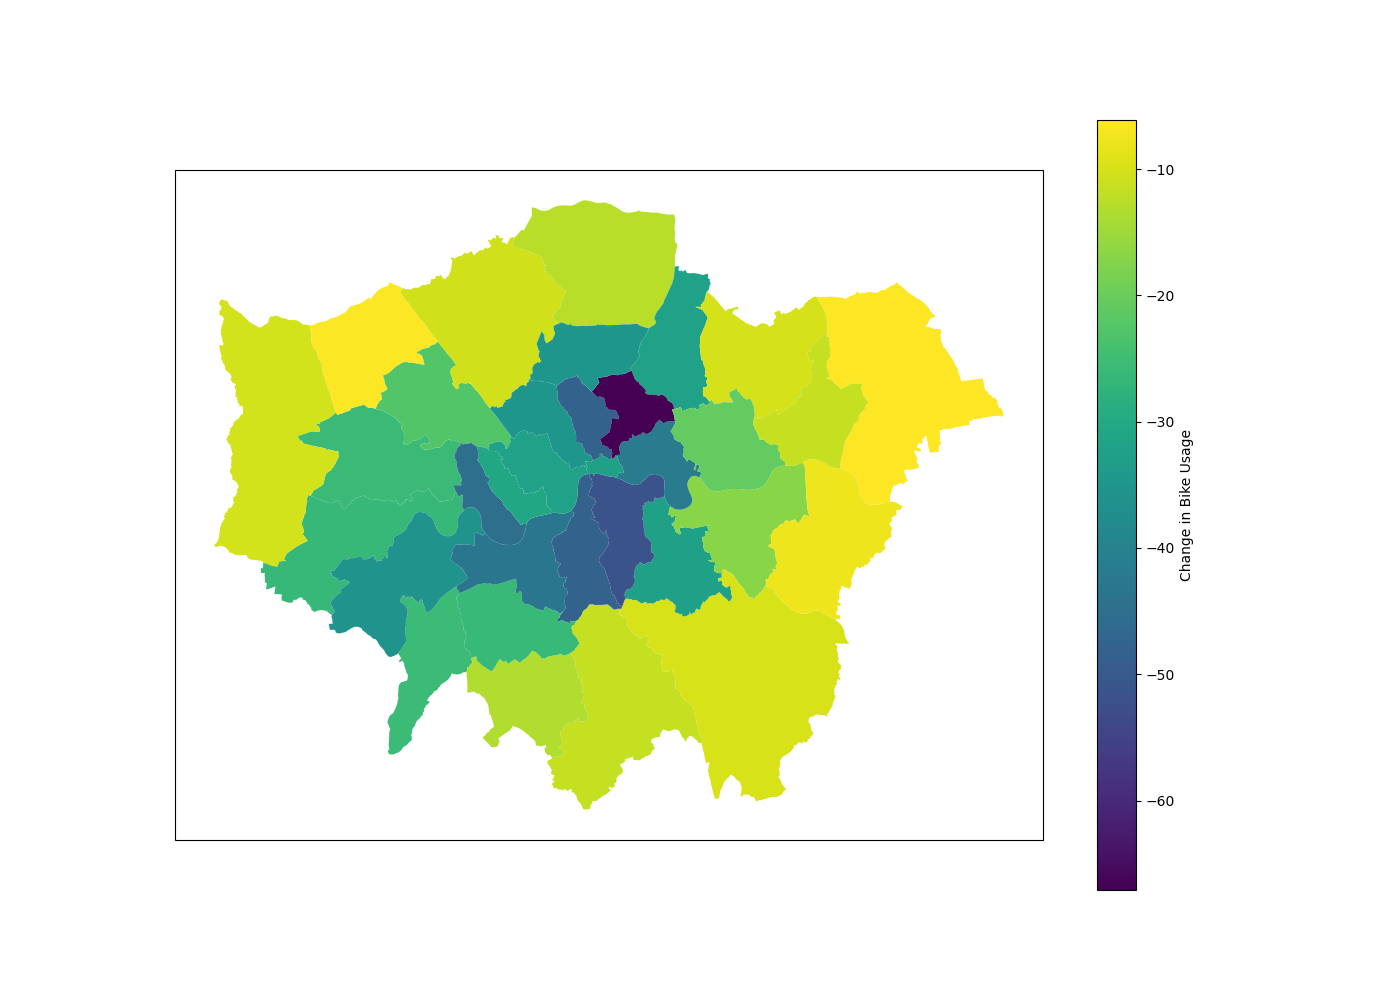

TypeError: 'GeometryArray' with dtype geometry does not support reduction 'min'

In [57]:
#set up chloropleth style map
travel_map['coords']=travel_map.geometry.centroid


fig, ax = plt.subplots(figsize=(14,10), subplot_kw={'projection':uni_crs})


travel_map.plot(column='bike_change',
                ax=ax,
                transform=uni_crs,
                cmap='viridis',
                legend=True,
                legend_kwds={'label':'Change in Bike Usage', 'orientation':'vertical'},
                aspect='equal')


plt.show()

travel_map.set_geometry('coords').plot(marker='^', markersize=4, alpha=0.8, zorder=2, ax=ax)
#this takes a white to process. create a new column for the marker at the top of the code

#can add names for each borough to the map
london = london.to_crs(uni_crs)


text_centroids = london.centroid.translate(xoff=200, yoff=500)
#use london dataset as the names are nicer
for idx, row in london.iterrows():
    point = text_centroids[idx]
    ax.annotate(text=row['name'],
    xy = (point.x, point.y),
    horizontalalignment='right',
    fontsize=6.5,
    color='k',
               zorder=3)

#it is hard to distinguish the marker from the name label. change this by using
#translate() function in the above function

#add cycle lanes
cycle = cycle_t.to_crs(uni_crs)
cycle.plot(ax=ax, linewidth=0.3, zorder=4, color='r')

cycle_handle = 

ax.legend(handles=cycle_handle,
          loc='upper right',
          title='Key',
          frameon=True)

In [ ]:
help(ax.plot)

In [ ]:
method_old['bike_change']

In [ ]:
print(method_old.columns)

In [ ]:
travel_map['bike_change']

In [45]:
cycle_t.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich